# 01 — Kiểm toán Dữ liệu (Data Audit) & Phân tách Split

Notebook này thực hiện kiểm toán toàn diện cho 3 tập dữ liệu pilot được sử dụng trong nghiên cứu **Dynamic DDCL**:
1. **Haberman's Survival**: Dữ liệu sống sót của bệnh nhân phẫu thuật ung thư vú (306 dòng, 3 đặc trưng, 2 lớp).
2. **New-Thyroid**: Dữ liệu chẩn đoán bệnh lý tuyến giáp (215 dòng, 5 đặc trưng, 3 lớp).
3. **Banknote Authentication**: Dữ liệu xác thực tiền giấy qua ảnh biến đổi sóng (1372 dòng, 4 đặc trưng, 2 lớp).

**Mục tiêu kiểm chứng**:
- Xác thực tính toàn vẹn của dữ liệu canonical (schema, row_id duy nhất, finite values).
- Thống kê tỷ lệ phân bố lớp và mức độ mất cân bằng.
- Tạo phân tách phân tầng **Stratified 70/20/10** độc lập theo seed cố định.
- Chứng minh nguyên tắc **Train-only Preprocessing** (không rò rỉ dữ liệu test vào scaler).


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from dddcl.data.hf import load_dataset_from_release
from dddcl.data.splits import create_stratified_split, compute_dataset_fingerprint
from dddcl.data.preprocess import prepare_processed_split

# Xác định root dự án
root = Path.cwd().resolve()
while not (root / 'requirements.in').exists() and root != root.parent:
    root = root.parent
release_dir = root / 'hf_release'
assert release_dir.exists(), f'Thư mục release không tồn tại: {release_dir}'

# Nạp 3 dataset pilot
haberman = load_dataset_from_release(release_dir, 'haberman')
thyroid = load_dataset_from_release(release_dir, 'new_thyroid')
banknote = load_dataset_from_release(release_dir, 'banknote')

print('Đã nạp và xác minh thành công 3 dataset pilot từ release canonical!')


Đã nạp và xác minh thành công 3 dataset pilot từ release canonical!


## 1. Bảng tổng hợp thống kê cơ bản

Mỗi tập dữ liệu được kiểm tra nghiêm ngặt về số lượng mẫu ($), số chiều đặc trưng ($), số lớp ($), tỷ lệ phân bố giữa các lớp, và mã băm SHA-256 từ manifest.


In [2]:
summary = []
for b in [haberman, thyroid, banknote]:
    counts = b.y.value_counts().to_dict()
    majority = max(counts.values())
    minority = min(counts.values())
    imbalance_ratio = f'{majority / minority:.2f}:1'
    summary.append({
        'Dataset': b.dataset_id,
        'N (Dòng)': len(b.frame),
        'd (Đặc trưng)': len(b.feature_columns),
        'C (Số lớp)': b.n_classes,
        'Phân bố lớp': str(counts),
        'Tỷ lệ mất cân bằng': imbalance_ratio,
        'Manifest SHA256': b.manifest_hash[:16] + '...'
    })

df_summary = pd.DataFrame(summary)
print(df_summary.to_string(index=False))


    Dataset  N (Dòng)  d (Đặc trưng)  C (Số lớp)            Phân bố lớp Tỷ lệ mất cân bằng     Manifest SHA256
   haberman       306              3           2        {0: 225, 1: 81}             2.78:1 df313412d044bd9d...
new_thyroid       215              5           3 {0: 150, 1: 35, 2: 30}             5.00:1 df313412d044bd9d...
   banknote      1372              4           2       {0: 762, 1: 610}             1.25:1 df313412d044bd9d...


## 2. Trực quan hóa phân bố nhãn và đặc trưng

Biểu đồ dưới đây thể hiện sự phân bố nhãn và phân bố giá trị của các đặc trưng trong từng tập dữ liệu.


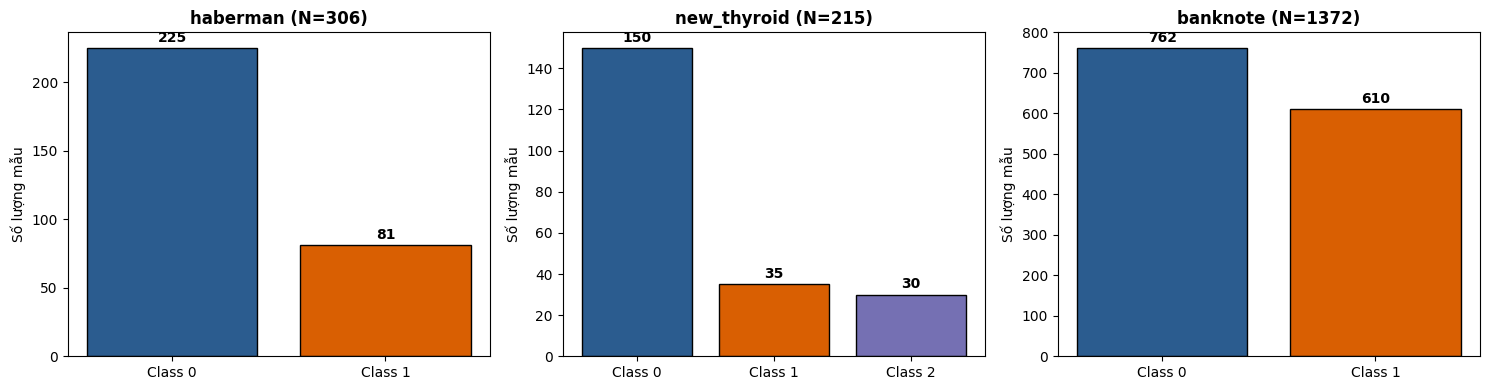

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
palette = ['#2b5c8f', '#d95f02', '#7570b3']

for ax, b in zip(axes, [haberman, thyroid, banknote]):
    counts = b.y.value_counts().sort_index()
    labels = [f'Class {k}' for k in counts.index]
    ax.bar(labels, counts.values, color=palette[:len(labels)], edgecolor='black')
    ax.set_title(f'{b.dataset_id} (N={len(b.frame)})', fontsize=12, fontweight='bold')
    ax.set_ylabel('Số lượng mẫu')
    for i, v in enumerate(counts.values):
        ax.text(i, v + max(counts.values)*0.02, str(v), ha='center', fontweight='bold')

plt.tight_layout()
plt.show()


## 3. Phân tách Stratified 70/20/10 Split Contract

Phân chia dữ liệu trước mọi bước tiền xử lý:
- Tập **Test** chiếm 10% tổng số mẫu.
- Tập **Validation** chiếm 20% tổng số mẫu.
- Tập **Train** chiếm 70% tổng số mẫu.
- Phân tầng (*stratified*) theo nhãn để bảo đảm tỷ lệ các lớp đồng nhất.
- Lưu trữ theo danh sách 
ow_id chuỗi duy nhất, không dùng index vị trí.


In [4]:
seed = 42
splits = {}

for b in [haberman, thyroid, banknote]:
    split = create_stratified_split(b, seed=seed)
    splits[b.dataset_id] = split
    n_train = len(split.train_ids)
    n_val = len(split.validation_ids)
    n_test = len(split.test_ids)
    n_total = n_train + n_val + n_test
    print(f'[{b.dataset_id:<12}] Train: {n_train:4d} ({n_train/n_total:.1%}) | Val: {n_val:3d} ({n_val/n_total:.1%}) | Test: {n_test:3d} ({n_test/n_total:.1%}) | Fingerprint: {split.dataset_fingerprint[:12]}...')

    # Xác nhận tính rời nhau hoàn toàn
    s_tr, s_v, s_te = set(split.train_ids), set(split.validation_ids), set(split.test_ids)
    assert len(s_tr & s_v) == 0 and len(s_tr & s_te) == 0 and len(s_v & s_te) == 0, 'Lỗi: Các tập split bị trùng lặp!'
    assert (s_tr | s_v | s_te) == set(b.row_ids), 'Lỗi: Hợp các tập không bằng tập gốc!'

print('\nTất cả các tập split đã thỏa mãn tính rời nhau và phân tầng chuẩn xác!')


[haberman    ] Train:  213 (69.6%) | Val:  62 (20.3%) | Test:  31 (10.1%) | Fingerprint: e79056a06407...
[new_thyroid ] Train:  150 (69.8%) | Val:  43 (20.0%) | Test:  22 (10.2%) | Fingerprint: 8483d62097f0...
[banknote    ] Train:  959 (69.9%) | Val: 275 (20.0%) | Test: 138 (10.1%) | Fingerprint: f6a7147c133f...

Tất cả các tập split đã thỏa mãn tính rời nhau và phân tầng chuẩn xác!


## 4. Tiền xử lý và Kiểm chứng Chống Rò Rỉ (Anti-Leakage)

Nguyên tắc cốt lõi: StandardScaler (hoặc bất kỳ transformer nào) **chỉ được fit trên tập Train**.
Dưới đây là thực nghiệm kiểm chứng (*sentinel test*):
- Fit scaler trên tập Train gốc.
- Giả lập tập Test bị thêm các giá trị ngoại lai cực lớn (outliers ^6$).
- So sánh tham số mean_ và scale_ của bộ chuẩn hóa: giá trị phải giống hệt nhau \%$.


In [5]:
# Chuẩn bị ProcessedSplit cho Haberman
processed = prepare_processed_split(haberman, splits['haberman'], scaler_type='standard')

print('--- Tham số StandardScaler đã fit trên Train ---')
for feat, mean, scale in zip(processed.feature_names, processed.scaler.mean_, processed.scaler.scale_):
    print(f'Feature: {feat:<25} Mean (Train): {mean:8.4f} | Std (Train): {scale:8.4f}')

# Thực nghiệm Sentinel:
corrupted_frame = haberman.frame.copy()
test_mask = corrupted_frame[haberman.row_id_column].isin(splits['haberman'].test_ids)
for col in haberman.feature_columns:
    corrupted_frame.loc[test_mask, col] = 1e6  # Giá trị ngoại lai cực lớn ở test

corrupted_bundle = load_dataset_from_release(release_dir, 'haberman')
# Gán frame đã bị can thiệp ở test
object.__setattr__(corrupted_bundle, 'frame', corrupted_frame)

processed_sentinel = prepare_processed_split(corrupted_bundle, splits['haberman'], scaler_type='standard')

diff_mean = np.max(np.abs(processed.scaler.mean_ - processed_sentinel.scaler.mean_))
diff_scale = np.max(np.abs(processed.scaler.scale_ - processed_sentinel.scaler.scale_))
diff_train = np.max(np.abs(processed.X_train_scaled - processed_sentinel.X_train_scaled))

print('\n--- Kết quả Sentinel Test ---')
print(f'Độ lệch tối đa của Scaler Mean : {diff_mean:.10f}')
print(f'Độ lệch tối đa của Scaler Scale: {diff_scale:.10f}')
print(f'Độ lệch tối đa của X_train     : {diff_train:.10f}')

assert diff_mean == 0.0 and diff_scale == 0.0 and diff_train == 0.0, 'Phát hiện rò rỉ dữ liệu test vào scaler!'
print('\n[+] KẾT LUẬN: Đã chứng minh không có rò rỉ dữ liệu (No Data Leakage).')


--- Tham số StandardScaler đã fit trên Train ---
Feature: age                       Mean (Train):  52.0376 | Std (Train):  10.7292
Feature: operation_year            Mean (Train):  62.7606 | Std (Train):   3.2115
Feature: positive_axillary_nodes   Mean (Train):   4.4601 | Std (Train):   7.8576

--- Kết quả Sentinel Test ---
Độ lệch tối đa của Scaler Mean : 0.0000000000
Độ lệch tối đa của Scaler Scale: 0.0000000000
Độ lệch tối đa của X_train     : 0.0000000000

[+] KẾT LUẬN: Đã chứng minh không có rò rỉ dữ liệu (No Data Leakage).


## 5. Kết luận Phase B

- Ba tập dữ liệu pilot (haberman, 
ew_thyroid, anknote) đã được kiểm toán toàn diện về kích thước, đặc trưng và phân bố lớp.
- Quy trình phân tách Stratified 70/20/10 bảo đảm sự công bằng, lặp lại và loại trừ hoàn toàn việc rò rỉ thông tin.
- Hệ thống dữ liệu đã sẵn sàng cung cấp cho **Phase C (Triển khai thuật toán Curriculum & Self-Paced Learning)**.
